# Train Price ETR Core and Full Models

This notebook trains both variants with identical chronological splits and saves them separately.

In [1]:
%pip install -q pandas scikit-learn joblib matplotlib seaborn

In [2]:
import json
import platform
import shutil
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from google.colab import drive
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesRegressor

drive.mount("/content/drive")

DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/demand-forecasting")
DRIVE_DATA_ROOT = DRIVE_PROJECT_DIR / "Dataset" / "price"
DRIVE_ARTIFACT_ROOT = DRIVE_PROJECT_DIR / "artifacts" / "price"
LOCAL_ARTIFACT_ROOT = Path("/content/price_etr_artifacts")
VARIANTS = ("core", "full")
DEVICE = "cpu"
TARGET_COLUMN = "future_weighted_avg_procurement_price_rm_per_kg"
CATEGORICAL_FEATURES = ["crop", "location", "origin_season", "target_season"]
EXCLUDED_FEATURES = ["forecast_origin_month", "target_month", TARGET_COLUMN]
VALIDATION_MONTHS = 3
TEST_MONTHS = 3

for variant in VARIANTS:
    expected = DRIVE_DATA_ROOT / variant / "price_horizon_training_dataset.csv"
    if not expected.exists():
        raise FileNotFoundError(f"Upload the {variant} dataset to: {expected}")
print("Both variant datasets found.")

Mounted at /content/drive
Both variant datasets found.


In [3]:
def load_and_split(variant):
    path = DRIVE_DATA_ROOT / variant / "price_horizon_training_dataset.csv"
    data = pd.read_csv(path, parse_dates=["forecast_origin_month", "target_month"])
    required = ["forecast_origin_month", "target_month", "forecast_horizon", *CATEGORICAL_FEATURES, TARGET_COLUMN]
    missing = [column for column in required if column not in data]
    if missing:
        raise ValueError(f"{variant} is missing required columns: {missing}")
    if data[TARGET_COLUMN].isna().any():
        raise ValueError(f"{variant} contains missing targets.")
    data = data.sort_values(["target_month", "forecast_origin_month", "crop", "location"]).reset_index(drop=True)
    final_month = data["target_month"].max().to_period("M").to_timestamp()
    test_start = final_month - pd.DateOffset(months=TEST_MONTHS - 1)
    validation_start = test_start - pd.DateOffset(months=VALIDATION_MONTHS)
    train = data[data["target_month"] < validation_start].copy()
    validation = data[data["target_month"].between(validation_start, test_start - pd.DateOffset(months=1))].copy()
    test = data[data["target_month"] >= test_start].copy()
    for name, frame in {"train": train, "validation": validation, "test": test}.items():
        if frame.empty or set(frame["forecast_horizon"].unique()) != set(range(1, 13)):
            raise ValueError(f"{variant} {name} split is empty or does not contain H1-H12.")
    return data, train, validation, test

def build_pipeline(feature_columns, numeric_features):
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    preprocessor = ColumnTransformer([
        ("categorical", categorical, CATEGORICAL_FEATURES),
        ("numeric", numeric, numeric_features),
    ], remainder="drop", verbose_feature_names_out=False)
    model = ExtraTreesRegressor(
        n_estimators=500, criterion="squared_error", max_depth=None,
        min_samples_split=2, min_samples_leaf=2, max_features=0.8,
        bootstrap=False, random_state=42, n_jobs=-1,
    )
    return Pipeline([("preprocessor", preprocessor), ("model", model)])

def metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.abs(actual).sum()
    return {
        "mae": float(mean_absolute_error(actual, predicted)),
        "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
        "wape": float(np.abs(actual - predicted).sum() / denominator) if denominator else np.nan,
        "r2": float(r2_score(actual, predicted)),
    }

In [4]:
all_metrics = []
variant_results = {}

for variant in VARIANTS:
    print(f"Training etr {variant} variant...")
    data, train, validation, test = load_and_split(variant)
    feature_columns = [column for column in data if column not in EXCLUDED_FEATURES]
    numeric_features = [column for column in feature_columns if column not in CATEGORICAL_FEATURES]
    unexpected_text = [column for column in numeric_features if not pd.api.types.is_numeric_dtype(data[column])]
    if unexpected_text:
        raise ValueError(f"{variant} features need encoding: {unexpected_text}")

    validation_pipeline = build_pipeline(feature_columns, numeric_features)
    validation_pipeline.fit(train[feature_columns], train[TARGET_COLUMN])
    validation_values = np.maximum(validation_pipeline.predict(validation[feature_columns]), 0)

    train_validation = pd.concat([train, validation], ignore_index=True).sort_values("target_month")
    final_pipeline = build_pipeline(feature_columns, numeric_features)
    final_pipeline.fit(train_validation[feature_columns], train_validation[TARGET_COLUMN])
    test_values = np.maximum(final_pipeline.predict(test[feature_columns]), 0)

    def prediction_table(frame, values, split_name):
        output = frame[["forecast_origin_month", "target_month", "crop", "location", "forecast_horizon", TARGET_COLUMN]].copy()
        output["etr_prediction"] = values
        output["split"] = split_name
        output["model_variant"] = variant
        output["absolute_error"] = (output[TARGET_COLUMN] - output["etr_prediction"]).abs()
        return output

    validation_predictions = prediction_table(validation, validation_values, "validation")
    test_predictions = prediction_table(test, test_values, "test")
    records = []
    for split_name, predictions in [("validation", validation_predictions), ("test", test_predictions)]:
        records.append({"model": "etr", "model_variant": variant, "split": split_name, "forecast_horizon": "overall", "rows": len(predictions), **metrics(predictions[TARGET_COLUMN], predictions["etr_prediction"])})
        for horizon, group in predictions.groupby("forecast_horizon"):
            records.append({"model": "etr", "model_variant": variant, "split": split_name, "forecast_horizon": int(horizon), "rows": len(group), **metrics(group[TARGET_COLUMN], group["etr_prediction"])})
    variant_metrics = pd.DataFrame(records)
    all_metrics.append(variant_metrics)

    local_root = LOCAL_ARTIFACT_ROOT / variant
    drive_root = DRIVE_ARTIFACT_ROOT / variant
    model_dir = local_root / "models"
    prediction_dir = local_root / "predictions"
    report_dir = local_root / "reports"
    for directory in [model_dir, prediction_dir, report_dir]:
        directory.mkdir(parents=True, exist_ok=True)
    joblib.dump(final_pipeline, model_dir / "global_etr_pipeline.joblib")
    validation_predictions.to_csv(prediction_dir / "etr_validation_predictions.csv", index=False)
    test_predictions.to_csv(prediction_dir / "etr_test_predictions.csv", index=False)
    variant_metrics.to_csv(report_dir / "etr_metrics.csv", index=False)
    metadata = {
        "model": "global_direct_multi_horizon_price_etr",
        "model_variant": variant,
        "requires_air_quality": variant == "full",
        "requires_fama": variant == "full",
        "stock_used": False,
        "target": TARGET_COLUMN,
        "feature_columns": feature_columns,
        "categorical_features": CATEGORICAL_FEATURES,
        "training_data_end": str(train_validation["target_month"].max().date()),
        "test_metrics": records[len(records) // 2],
        "versions": {"python": platform.python_version(), "pandas": pd.__version__, "scikit_learn": sklearn.__version__, "joblib": joblib.__version__},
    }
    (report_dir / "etr_training_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    for source in local_root.rglob("*"):
        if source.is_file():
            destination = drive_root / source.relative_to(local_root)
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, destination)
    variant_results[variant] = {"test": test_predictions, "metrics": variant_metrics}
    print(f"Saved {variant} artifacts to {drive_root}")

comparison = pd.concat(all_metrics, ignore_index=True)
display(comparison[(comparison["split"] == "test") & (comparison["forecast_horizon"] == "overall")].sort_values("mae"))

Training etr core variant...
Saved core artifacts to /content/drive/MyDrive/demand-forecasting/artifacts/price/core
Training etr full variant...
Saved full artifacts to /content/drive/MyDrive/demand-forecasting/artifacts/price/full


,model,model_variant,split,forecast_horizon,rows,mae,rmse,wape,r2
39,etr,full,test,overall,1620,0.170201,0.213166,0.037283,0.986322
13,etr,core,test,overall,1620,0.170507,0.213623,0.037350,0.986264


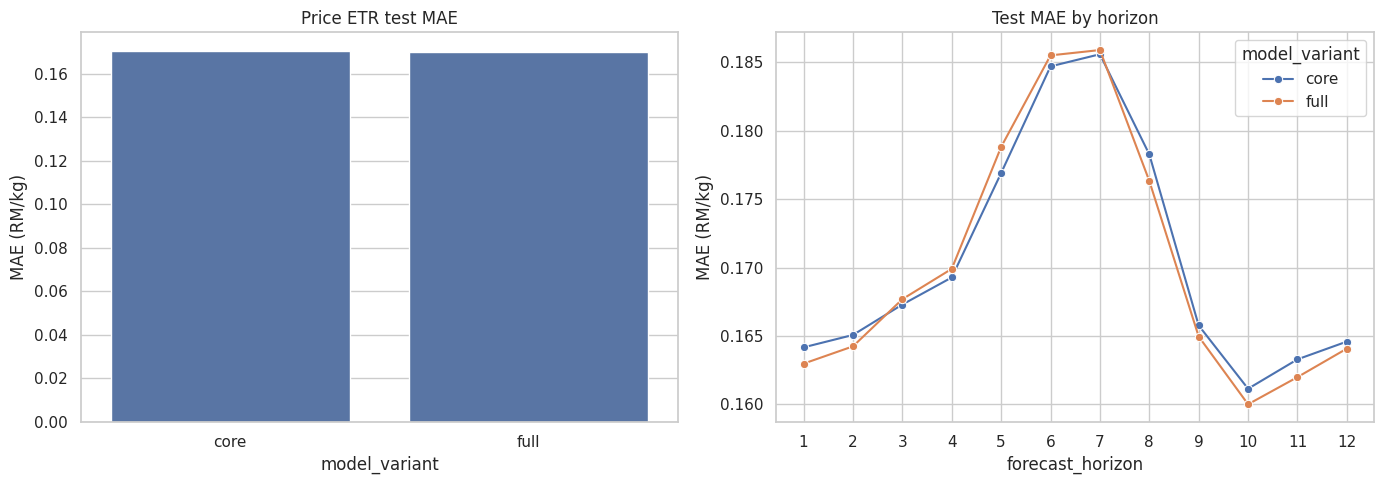

In [5]:
sns.set_theme(style="whitegrid")
test_overall = comparison[(comparison["split"] == "test") & (comparison["forecast_horizon"] == "overall")]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=test_overall, x="model_variant", y="mae", ax=axes[0])
axes[0].set_title("Price ETR test MAE")
axes[0].set_ylabel("MAE (RM/kg)")
horizon_metrics = comparison[(comparison["split"] == "test") & (comparison["forecast_horizon"] != "overall")].copy()
horizon_metrics["forecast_horizon"] = horizon_metrics["forecast_horizon"].astype(int)
sns.lineplot(data=horizon_metrics, x="forecast_horizon", y="mae", hue="model_variant", marker="o", ax=axes[1])
axes[1].set_title("Test MAE by horizon")
axes[1].set_xticks(range(1, 13))
axes[1].set_ylabel("MAE (RM/kg)")
plt.tight_layout()
plt.show()